# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 8</span>


The variational principle in Quantum Mechanics states that the expectation value of the Hamiltonian over a (good) trial quantum state has the ground state energy $E_0$ as lower bound:

$$
\langle {\hat H} \rangle_T = 
\frac{\int dx \Psi^*_T(x) {\hat H} \Psi_T(x)}
{\int dx |\Psi_T(x)|^2} \ge E_0 =
\frac{\langle \Psi_0| {\hat H} | \Psi_0 \rangle}
{\langle \Psi_0 | \Psi_0 \rangle}
$$

During this exercise you will variationally optimize the ground state of a single quantum particle in a one dimensional (1D) space confined by the following external potential:
$$
V(x) = x^4 - \frac{5}{2}x^2
$$

This 1D quantum model is not analytically solvable and should be attacked by numerical methods. In order to obtain an approximate wave function for the ground state, the Variational Monte Carlo method uses a trial wave function, parametrized by a set of variational parameters. An approximate model for the ground state wave function is the following trial wave function:
$$
\Psi_T^{\sigma,\mu}(x) \propto e^{-\frac{(x-\mu)^2}{2\sigma^2}}+
                               e^{-\frac{(x+\mu)^2}{2\sigma^2}}
$$

$\Psi_T^{\sigma,\mu}(x)$ depends on two variational parameters: $\sigma$ and $\mu$.

### Exercise 08.1

Write a Variational Monte Carlo code for a single quantum particle in 1D which exploits the Metropolis algorithm to sample the square modulus of our trial wave function $|\Psi_T^{\sigma,\mu}(x)|^2$ using an uniform transition probability $T(x_{new}|x_{old})$. By using data blocking, the code should be able to compute the expectation value for the Hamiltonian

$$
\langle {\hat H} \rangle_T = 
\frac{\int dx \Psi^*_T(x) {\hat H} \Psi_T(x)}
{\int dx |\Psi_T(x)|^2} = 
\int dx \frac{|\Psi_T(x)|^2}{\int dx |\Psi_T(x)|^2} \frac{{\hat H} \Psi_T(x)}{\Psi_T(x)}
$$

which can be used to find the parameters that minimize this quantity. Use $\hbar = 1$ and $m=1$.
Note that to measure $\langle {\hat H} \rangle_T$ you need the analytical calculation of:
    
$$
\frac{{-\frac{\hbar^2}{2m}\frac{\partial^2}{\partial x^2}} \Psi_T^{\sigma,\mu}(x)}{\Psi_T^{\sigma,\mu}(x)}
$$

### Exercise 08.2

To find the parameters $\sigma$ and $\mu$ which minimize $\langle {\hat H} \rangle_T$, extend your Variational Monte Carlo code to face the variational optimization problem via a <span style="color:red">Simulated Annealing (SA) algorithm</span>.

Choose an appropriate starting temperature for your SA algorithm and an appropriate temperature-update-law to make the optimization work.

Compute $\langle {\hat H} \rangle_T$ with enough statistics in order to be able to measure the lowering of $\langle {\hat H} \rangle_T$ once the variational parameters are moved.

- Show a picture of $\langle {\hat H} \rangle_T$ (with statistical uncertainties) as a function of the SA steps of the algorithm
- you could also show a picture of the trajectory of the SA algorithm in the variational parameter space as a function of the SA steps
- show a picture of the estimation of $\langle {\hat H} \rangle_T$  and its statistical uncertainty as a function of the number of blocks/MC steps for the set of parameters which minimize $\langle {\hat H} \rangle_T$
- show also a picture **of the sampled** $|\Psi_T(x)|^2$ by filling a histogram with the sampled configurations, moreover compare it with the analytic curve of $|\Psi_T(x)|^2$ and with the numerical solution obtained by transforming the Schrodinger equation into a matrix equation (see below the supplementary material).

### <span style="color:green">Supplementary material</span>

How can we describe a wave function as a vector? We set up a lattice of discrete points, spaced by a constant distance $dx$, and record the value of the function at each lattice point. In this way the wave function, $\Psi(x)$ become a vector:

$$
\Psi(x) \to \left[ \Psi(x_1), \Psi(x_2), ..., \Psi(x_N) \right] = 
\left[ \Psi_1, \Psi_2, ..., \Psi_N \right]
$$

The time independent Schrodinger equation 

$$
{\hat H} \Psi(x) = \left( -\frac{\hbar^2}{2m}\frac{\partial^2}{\partial x^2} + V(x) \right) \Psi(x) = E \Psi(x)
$$

can be written in matrix form. But how do we write the second derivative at a particular point? Let's start with the first derivatives:
$$
\frac{\partial}{\partial x} \Psi\left(x=(x_i+x_{i+1})/2\right) \simeq \frac{\Psi_{i+1}-\Psi_{i}}{dx}\\
\frac{\partial}{\partial x} \Psi\left(x=(x_i+x_{i-1})/2\right) \simeq \frac{\Psi_{i}-\Psi_{i-1}}{dx}
$$

Thus, we can discretize the second derivative in the following way:
$$
\frac{\partial^2}{\partial x^2} \Psi(x=x_i) =
\frac{\frac{\partial}{\partial x} \Psi\left(x=(x_i+x_{i+1})/2\right) - \frac{\partial}{\partial x} \Psi\left(x=(x_i+x_{i-1})/2\right)}{dx} =
\frac{\Psi_{i+1}-2\Psi_{i}+\Psi_{i-1}}{dx^2}
$$

We finally obtain:

$$
\begin{bmatrix}
 \frac{\hbar^2}{m\,dx^2}+V(x_1)& -\frac{\hbar^2}{2m\,dx^2} & 0 & \dots  & 0 \\
-\frac{\hbar^2}{2m\,dx^2} & \frac{\hbar^2}{m\,dx^2}+V(x_2) & -\frac{\hbar^2}{2m\,dx^2} & \dots  & 0 \\
 0                        & -\frac{\hbar^2}{2m\,dx^2} & \frac{\hbar^2}{m\,dx^2}+V(x_3) & \dots  & 0 \\
 \vdots                   & \vdots                    & \vdots & \ddots & \vdots \\
 0                    & 0                & 0 & \dots  & \frac{\hbar^2}{m\,dx^2}+V(x_N)
\end{bmatrix}
\begin{bmatrix}
\Psi_{1} \\
\Psi_{2} \\
\vdots \\
\Psi_{N}
\end{bmatrix}
= E
\begin{bmatrix}
\Psi_{1} \\
\Psi_{2} \\
\vdots \\
\Psi_{N}
\end{bmatrix}
$$

To solve the time independent Schrodinger equation we therefore have to find eigenstates and eigenvalues of the matrix just obtained.

Ground state energy:  -0.4604658796933896
1st excited state energy:  0.09742471331728086
2nd excited state energy:  1.9717331343925388


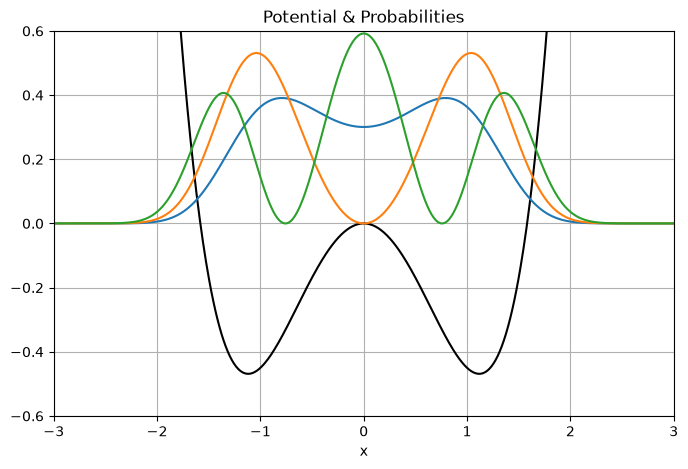

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def Vpot(x):
    return (x**2 - 2.5)*x**2
    #return 0.5*x**2

hbar = 1
m = 1
a = 10
N = 1000 # number of iterations

# Step sizes
x = np.linspace(-a/2, a/2, N)
dx = x[1] - x[0] # the step size
V = Vpot(x)

# The central differences method: f" = (f_1 - 2*f_0 + f_-1)/dx^2

CDiff = np.diag(np.ones(N-1),-1)-2*np.diag(np.ones(N),0)+np.diag(np.ones(N-1),1)
# np.diag(np.array,k) construct a "diagonal" matrix using the np.array
# The default is k=0. Use k>0 for diagonals above the main diagonal, 
# and k<0 for diagonals below the main diagonal

# Hamiltonian matrix
H = (-(hbar**2)*CDiff)/(2*m*dx**2) + np.diag(V)

# Compute eigenvectors and their eigenvalues
E,psi = np.linalg.eigh(H)
E0 = E[0]

# Take the transpose & normalize
psi = np.transpose(psi)
psi = psi/np.sqrt(dx)

print("Ground state energy: ", E[0])
print("1st excited state energy: ", E[1])
print("2nd excited state energy: ", E[2])

# Plot a few things
plt.figure(figsize=(8,5))
scale = 0.3
plt.plot(x, scale*V, color="Black", label="Potential") # plot the potential
plt.plot(x,(psi[0])**2)
plt.plot(x,(psi[1])**2)
plt.plot(x,(psi[2])**2)
plt.title("Potential & Probabilities")
plt.xlabel("x")
plt.grid(True)
plt.xlim((-3,3))
plt.ylim((-0.6,0.6))
plt.show()

# <span style="color:green"> RESULTS: </span>

In this notebook we computed the ground state of a quantum particle in one dimension, in the potential $V(x)=x^4-\frac52x^2$ (with $\hbar=m=1$), using a Variational Monte Carlo (VMC) code. To sample the square modulus of a trial wave function we used a Metropolis algorithm with a uniform transition probability, then we optimised the variational parameters with a Simulated Annealing (SA) algorithm. Finally, we compared the results with the numerical solution of the Schrödinger equation obtained with the matrix method.

The trial wave function we used is the sum of two Gaussians centred in $\pm\mu$, with width $\sigma$:
$$
\Psi_T^{\sigma,\mu}(x) \propto e^{-\frac{(x-\mu)^2}{2\sigma^2}} + e^{-\frac{(x+\mu)^2}{2\sigma^2}}
$$
This function is symmetric and can describe the two wells of the potential. By the variational principle $\langle\hat H\rangle_T\ge E_0$ for any choice of the parameters $\mu$ and $\sigma$, so the best parameters are the ones that minimise $\langle\hat H\rangle_T$.

### Exercise 8.1

In the first exercise we computed the expectation value of the Hamiltonian $\langle\hat H\rangle_T$ for fixed values of $\mu$ and $\sigma$, sampling $|\Psi_T|^2$ with the Metropolis algorithm:
$$
\langle\hat H\rangle_T=\int dx\,\frac{|\Psi_T(x)|^2}{\int dx\,|\Psi_T(x)|^2}\,E_{loc}(x),\qquad E_{loc}(x)=\frac{\hat H\Psi_T(x)}{\Psi_T(x)}=-\frac12\frac{\Psi_T''(x)}{\Psi_T(x)}+V(x)
$$
so it can be estimated as the average of the local energy $E_{loc}$ over positions $x$ sampled from $|\Psi_T(x)|^2$. The second derivative of the trial function is computed analytically:
$$
\Psi_T''(x)=\left[\frac{(x-\mu)^2}{\sigma^4}-\frac1{\sigma^2}\right]e^{-\frac{(x-\mu)^2}{2\sigma^2}}+\left[\frac{(x+\mu)^2}{\sigma^4}-\frac1{\sigma^2}\right]e^{-\frac{(x+\mu)^2}{2\sigma^2}}
$$

The trial move of the Metropolis algorithm is uniform, $x_{new}=x_{old}+\mathcal U(-\delta,\delta)$, so the transition probability is symmetric and the move is accepted with probability 
$$
min\left[1,\,\frac{|\Psi_T(x_{new})|^2}{|\Psi_T(x_{old})|^2}\right]
$$.
The normalisation of $\Psi_T$ is not needed, because only the ratio of the two probabilities enters and the normalisation constant cancels. 

We used a step proportional to the width of the wave function, $\delta=2.5\,\sigma$ (so $\delta=1.5$ for $\sigma=0.6$), which keeps the acceptance rate in a reasonable range when $\sigma$ changes; this will be important for the SA, where $\sigma$ is varied. For $(\mu,\sigma)=(0.8,0.6)$ the acceptance rate is $67.8\%$. The walker starts from $x=\mu$ and the first $20000$ steps are discarded to equilibrate it. The algorithm is implemented in the class <small><code>Metropolis</code></small>, which takes the distribution to be sampled as a function, so it can be reused for any $|\Psi_T|^2$:
<small>
```cpp
double x_new = m_x + rnd.Rannyu(-m_delta, m_delta);        // uniform trial move
double p_metropolis = std::min(1.0, pdf(x_new) / pdf(m_x));   // acceptance probability
if (rnd.Rannyu() < p_metropolis) { m_x = x_new; m_accepted++; }
```
</small>

The statistical uncertainty on $\langle\hat H\rangle_T$ is computed with data blocking, using $N=200$ blocks of $L=5000$ steps. The plots below show, for $(\mu,\sigma)=(0.8,0.6)$, the progressive average of $\langle\hat H\rangle_T$ as a function of the number of blocks, with its statistical uncertainty and compared with the value obtained by numerical integration, and the histogram of the sampled positions compared with the analytic $|\Psi_T(x)|^2$:



In [24]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [25]:
mu1, sigma1 = 0.8, 0.6

block, average_ham, error = np.loadtxt('./OUTPUT/HamiltonianExpValue_0.8_0.6.dat', unpack=True)
step, x_coord = np.loadtxt('./OUTPUT/Coordinates_0.8_0.6.dat', unpack=True)

In [26]:
xx = np.linspace(-6, 6, 4000)
dxx = xx[1] - xx[0]

def psi_T(x, mu, sigma):
    return np.exp(-(x - mu)**2 / (2*sigma**2)) + np.exp(-(x + mu)**2 / (2*sigma**2))

def p_T(x, mu, sigma):
    """Normalised |Psi_T|^2 (normalisation computed numerically on the grid xx)."""
    norm = (psi_T(xx, mu, sigma)**2).sum() * dxx
    return psi_T(x, mu, sigma)**2 / norm

def e_loc(x, mu, sigma):
    """Local energy H Psi_T / Psi_T."""
    A = np.exp(-(x - mu)**2 / (2*sigma**2))
    B = np.exp(-(x + mu)**2 / (2*sigma**2))
    kin = 1/(2*sigma**2) - ((x - mu)**2 * A + (x + mu)**2 * B) / (2*sigma**4 * (A + B))
    return kin + Vpot(x)

def exact_H(mu, sigma):
    """<H>_T computed by numerical integration (reference for the Monte Carlo estimate)."""
    return (p_T(xx, mu, sigma) * e_loc(xx, mu, sigma)).sum() * dxx

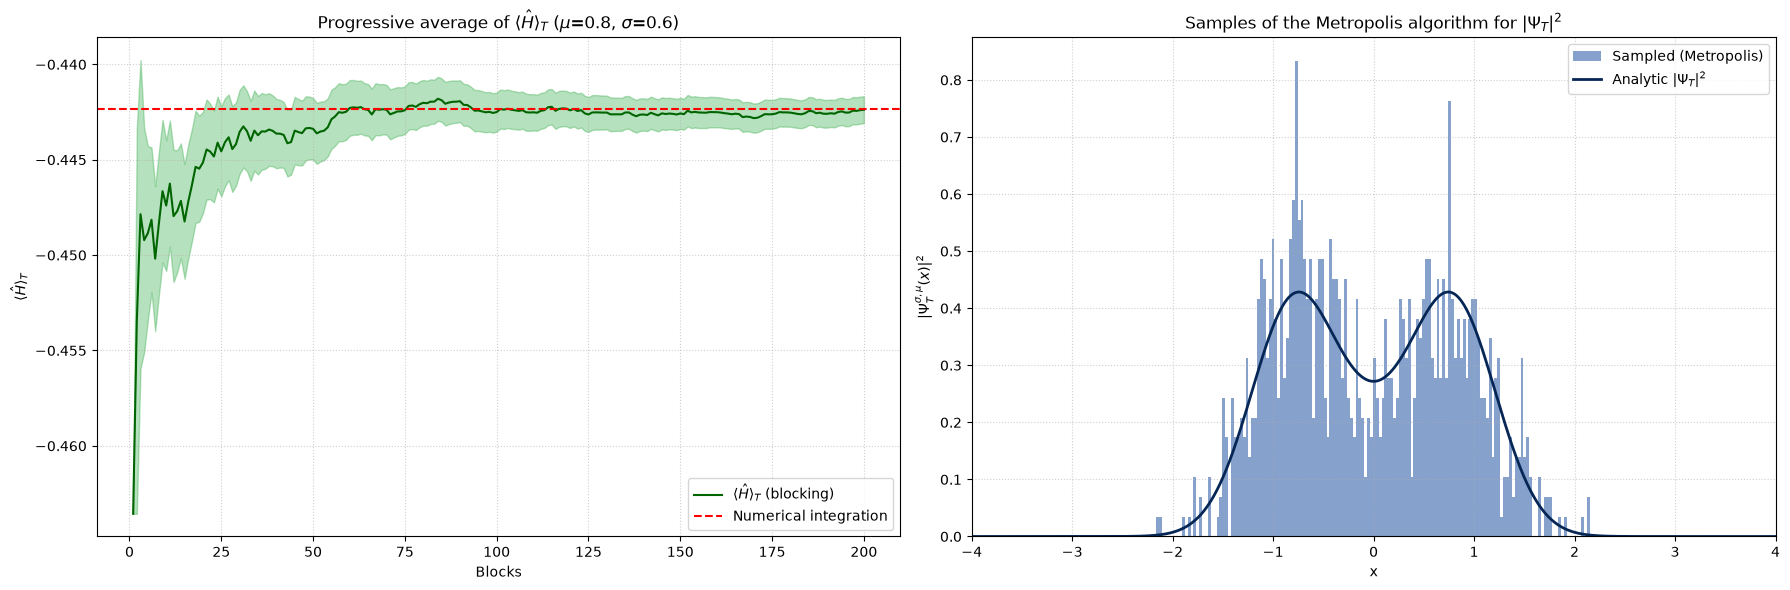

<H>_T = -0.44238 +- 0.00071   (numerical integration: -0.44236)


In [27]:
fig, ax = plt.subplots(1, 2, figsize=(18, 6))

# progressive average of <H>_T (data blocking) vs number of blocks
ax[0].plot(block, average_ham, color='darkgreen', lw=1.5, label=r'$\langle \hat{H} \rangle_T$ (blocking)')
ax[0].fill_between(block, average_ham - error, average_ham + error, color='#109e28', alpha=0.3)
ax[0].axhline(exact_H(mu1, sigma1), color='r', ls='--', label='Numerical integration')
ax[0].set_xlabel('Blocks'); ax[0].set_ylabel(r'$\langle \hat{H} \rangle_T$')
ax[0].set_title(rf'Progressive average of $\langle \hat{{H}} \rangle_T$ ($\mu$={mu1}, $\sigma$={sigma1})')

# sampled |Psi_T|^2 Vs analytic curve
ax[1].hist(x_coord, bins=150, density=True, color='#0c459a', alpha=0.5, label='Sampled (Metropolis)')
ax[1].plot(xx, p_T(xx, mu1, sigma1), '-', color = "#062655",  lw=2, label=r'Analytic $|\Psi_T|^2$')
ax[1].set_xlim(-4, 4)
ax[1].set_xlabel('x'); ax[1].set_ylabel(r'$|\Psi_T^{\sigma,\mu}(x)|^2$')
ax[1].set_title('Samples of the Metropolis algorithm for $|\Psi_T|^2$')

for a_ in ax: a_.grid(True, ls=':', alpha=0.6); a_.legend()
plt.tight_layout(); plt.show()

print(f"<H>_T = {average_ham[-1]:.5f} +- {error[-1]:.5f}   (numerical integration: {exact_H(mu1, sigma1):.5f})")

The progressive average converges to $\langle\hat H\rangle_T=-0.44238\pm0.00071$, in agreement with the exact value of $\langle\hat H\rangle_T$ for these parameters, obtained by numerical integration, $-0.44236$: the difference is approximatly $0.03\sigma$, much smaller than the statistical error. The histogram of the sampled positions reproduces the analytic $|\Psi_T|^2$, with two peaks close to $x=\pm\mu$ and a minimum at the origin that does not vanish, because the two Gaussians overlap. This validates both the sampling and the computation of the local energy.

### Exercise 8.2

To find the parameters that minimise $\langle\hat H\rangle_T$ we used the Simulated Annealing (SA) algorithm, which is a Metropolis algorithm in the space of the parameters $(\mu,\sigma)$ in which the temperature is slowly lowered. The "energy" is $\langle\hat H\rangle_T(\mu,\sigma)$, computed with the VMC of the previous exercise. At every step a new set of parameters is proposed by adding to the current ones a Gaussian random number with zero mean and standard deviation $s(T)=0.5\,T/T_{max}$, and it is accepted with probability $\min\left[1,e^{-\Delta E/T}\right]$, where $\Delta E$ is the change of $\langle\hat H\rangle_T$. The moves that lower the energy are always accepted, while the others are accepted with a probability that decreases with $T$: at high temperature the algorithm explores the parameter space widely and can escape from local minima, and as $T\to0$ it settles in a minimum. The width of the proposal decreases with the temperature, so the first moves are large and the last ones are small refinements around the minimum. Since $\Psi_T$ does not change if the sign of $\mu$ or $\sigma$ is flipped, the parameters are taken in absolute value, and $\sigma$ is bounded below by $0.01$ to avoid a vanishing width: 
<small>
```cpp
double shrink = T/T_max;    // the width of the proposal decreases with the temperature
return quant::Params{ fabs(state.mu + rnd.Gauss(0., 0.5*shrink)),
                       max(fabs(state.sigma + rnd.Gauss(0., 0.5*shrink)), 0.01) };
```
</small>

We used a geometric cooling law $T\to rT$ with $r=0.997$, from $T_{max}=1$ to $T_{min}=0.001$, with one SA step per temperature, for a total of about $2300$ steps. The SA starts from $(\mu,\sigma)=(1,1)$. Since each $\langle\hat H\rangle_T$ is a noisy estimate, every evaluation uses $N=100$ blocks of $L=2000$ steps ($2\cdot10^5$ steps, after $20000$ steps of equilibration), with the Metropolis step $\delta=2.5\,\sigma$ of the previous exercise. Near the minimum the statistical error of each evaluation, computed with data blocking, is about $0.0019$, so the SA cannot distinguish parameters whose energies differ by less than this value. The set of parameters with the lowest energy found during the annealing is then used for a final simulation with higher statistics using $N=100$ blocks of $L=10^4$ steps, because it was selected among noisy estimates and its energy has to be recomputed independently.

The following graphs show the energy $\langle\hat H\rangle_T$ along the SA together with the temperature, the trajectory of the parameters in the $(\mu,\sigma)$ plane and in the energy landscape, with $\langle\hat H\rangle_T$ as third axis:

In [ ]:
step, temp, mu, sigma, h_val, err, best_h = np.loadtxt('./OUTPUT/HamiltonianExpValue.dat', unpack=True)
total_steps = len(mu)
mu_opt, sigma_opt = mu[-1], sigma[-1] 

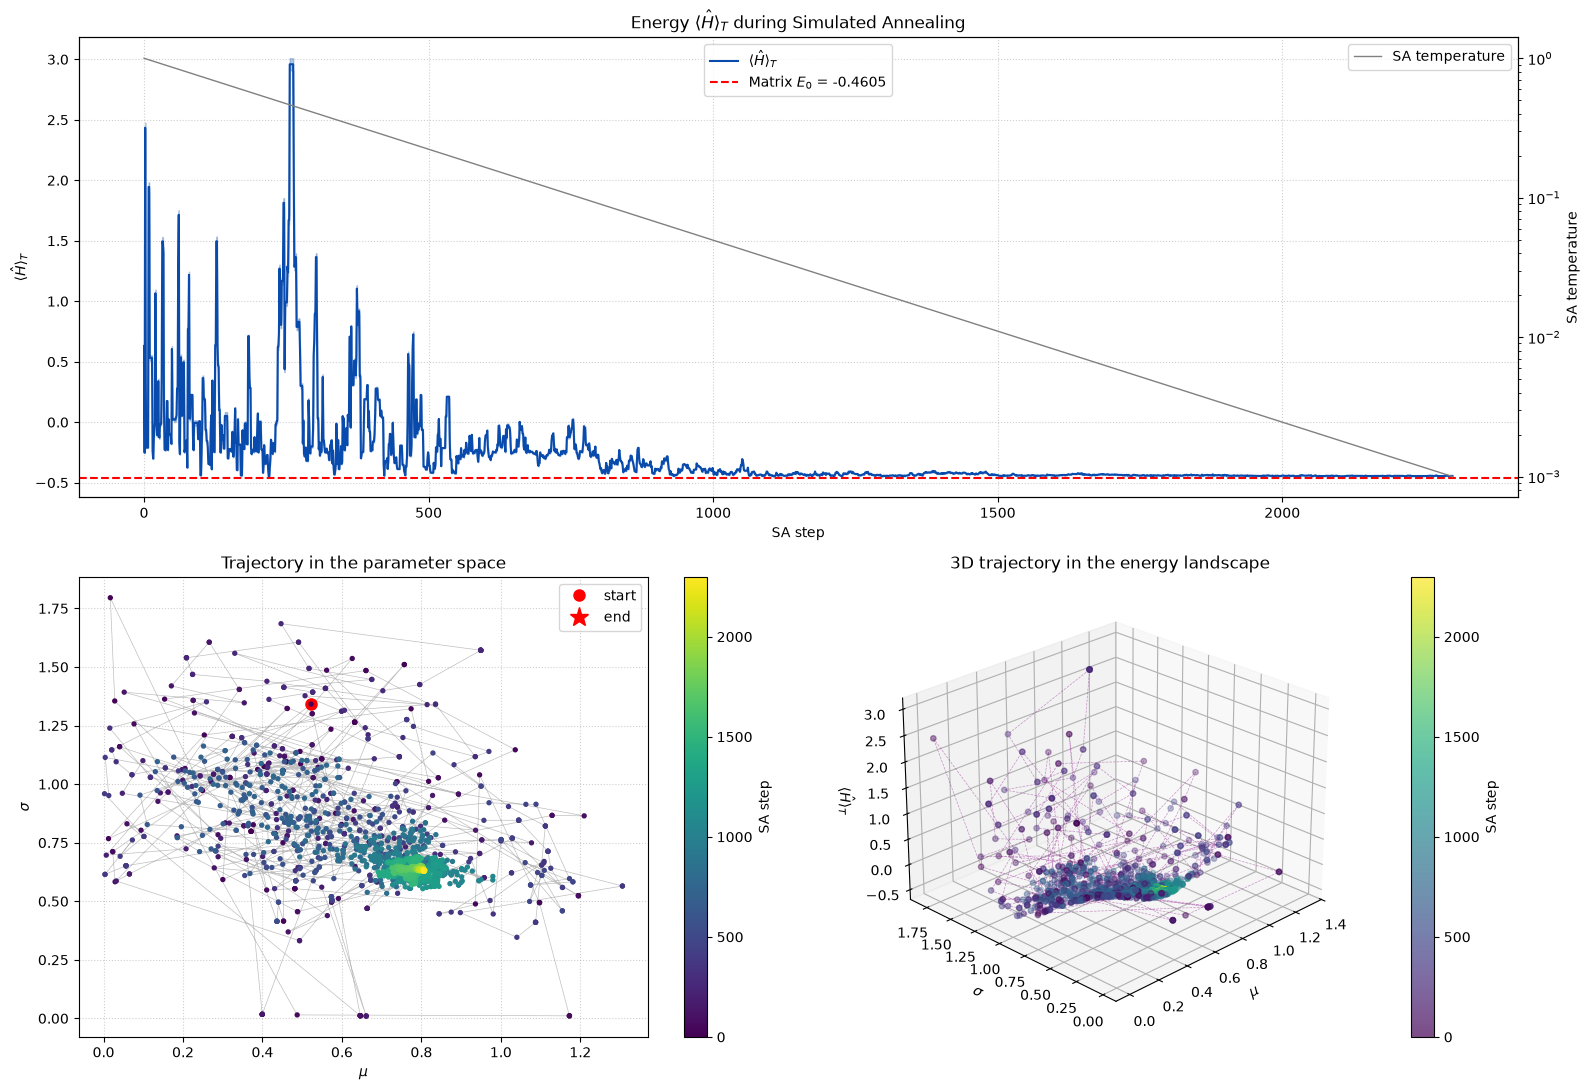

Best parameters found: mu = 0.8055, sigma = 0.6277
<H>_T at the start: 0.6297   at the end: -0.4444 +- 0.0019   (matrix E0 = -0.4605)


In [ ]:
fig = plt.figure(figsize=(16, 11))
ax_A = fig.add_subplot(2, 2, (1, 2))                  
ax_B = fig.add_subplot(2, 2, 3)                        
ax_C = fig.add_subplot(2, 2, 4, projection='3d')        

# <H>_T vs SA step, with the SA temperature on a second axis
ax_A.plot(step, h_val, color="#094bac", lw=1.5, label=r'$\langle \hat{H} \rangle_T$')
ax_A.fill_between(step, h_val - err, h_val + err, color="#094bac", alpha=0.3)
ax_A.axhline(E0, color='r', ls='--', label=rf'Matrix $E_0$ = {E0:.4f}')
ax_A.set_xlabel('SA step'); ax_A.set_ylabel(r'$\langle \hat{H} \rangle_T$')
ax_A.set_title(r'Energy $\langle \hat{H} \rangle_T$ during Simulated Annealing')
ax_A.grid(True, ls=':', alpha=0.6); ax_A.legend(loc='upper center')

ax_T = ax_A.twinx()
ax_T.plot(step, temp, color='gray', lw=1, label='SA temperature')
ax_T.set_yscale('log'); ax_T.set_ylabel('SA temperature'); ax_T.legend(loc='upper right')

# 2D trajectory in the (mu, sigma) plane 
ax_B.plot(mu, sigma, color='gray', lw=0.5, alpha=0.5)                
sc_B = ax_B.scatter(mu, sigma, c=step, cmap='viridis', s=8, zorder=3)
ax_B.plot(mu[0], sigma[0], 'ro', ms=8, label='start')
ax_B.plot(mu_opt, sigma_opt, 'r*', ms=14, label='end')
fig.colorbar(sc_B, ax=ax_B, label='SA step')
ax_B.set_xlabel(r'$\mu$'); ax_B.set_ylabel(r'$\sigma$')
ax_B.set_title('Trajectory in the parameter space')
ax_B.grid(True, ls=':', alpha=0.6); ax_B.legend()

# 3D trajectory <H>_T as a function of the parameters
ax_C.plot(mu, sigma, h_val, color='purple', lw=0.5, alpha=0.4, ls='--')
sc_C = ax_C.scatter(mu, sigma, h_val, c=step, cmap='viridis', s=15, alpha=0.7)
fig.colorbar(sc_C, ax=ax_C, label='SA step', pad=0.1)
ax_C.set_xlabel(r'$\mu$'); ax_C.set_ylabel(r'$\sigma$'); ax_C.set_zlabel(r'$\langle \hat{H} \rangle_T$')
ax_C.set_title('3D trajectory in the energy landscape')
ax_C.view_init(elev=25, azim=-135)

plt.tight_layout()
plt.show()

print(f"Best parameters found: mu = {mu_opt:.4f}, sigma = {sigma_opt:.4f}")
print(f"<H>_T at the start: {h_val[0]:.4f}   at the end: {h_val[-1]:.4f} +- {err[-1]:.4f}   (matrix E0 = {E0:.4f})")

At high temperature the energy fluctuates widely up to $\approx3$, because the algorithm accepts moves that largely increase the energy and visits parameters far from the minimum as also shown from the trajectory in the parameter plane that covers the whole region, with $\sigma$ up to $\approx1.8$. As $T$ decreases the fluctuations shrink. After about 1000 steps correnponding to a temperature of $T\simeq0.05$ the energy settles close to the ground state energy $E_0=-0.4605$ obtained with the matrix method, and the parameters concentrate in a small region around $\mu\approx0.8$, $\sigma\approx0.6$. In the 3D plot we can see that the late points lie at the bottom of the energy landscape. The SA found the best parameters to be $\mu=0.806$, $\sigma=0.628$.

Using the best parameters found by the SA, we repeated the VMC simulation with higher statistics ($N=100$ blocks of $L=10^4$ steps) and produced the same graphs as in Exercise 8.1, adding the ground state energy $E_0$ and the ground state probability density obtained with the matrix method, to compare them with our trial function:

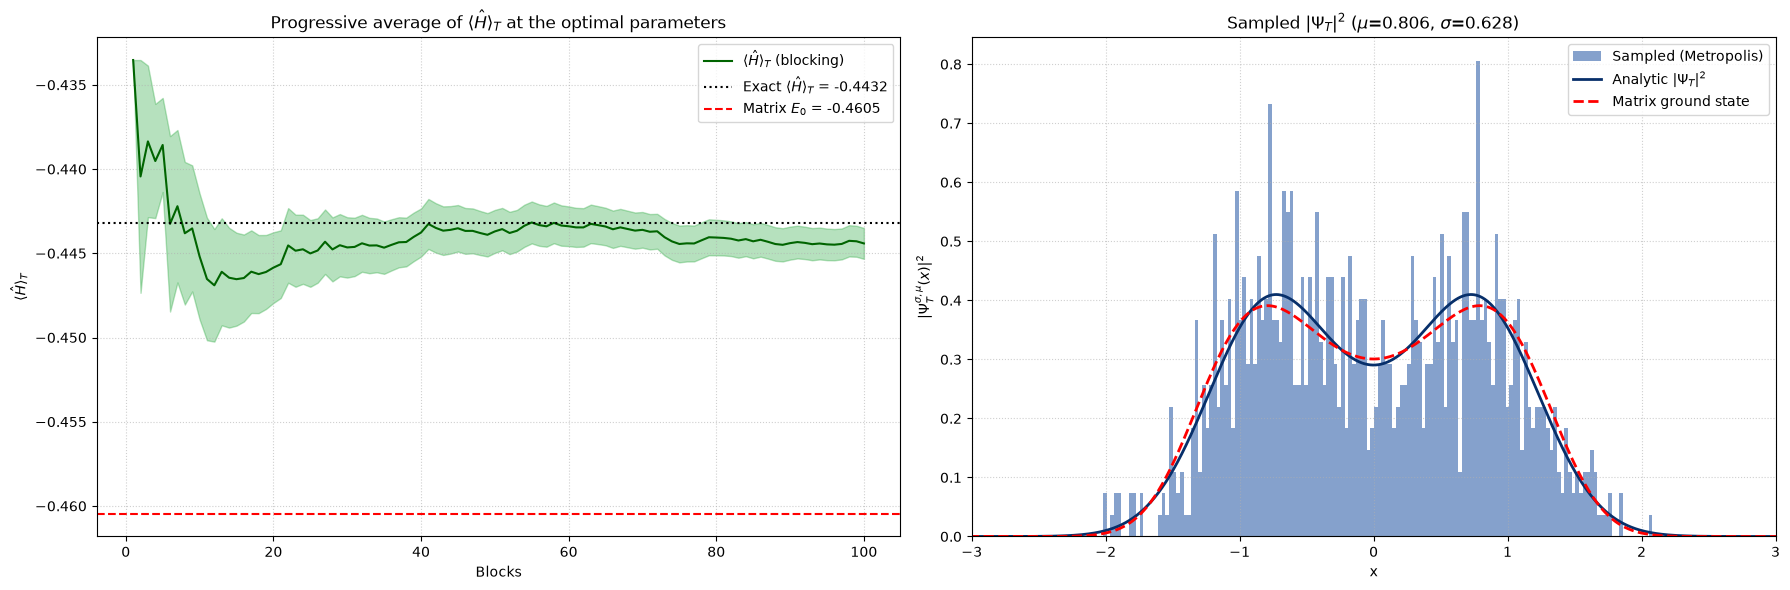

<H>_T = -0.44441 +- 0.00092
Numerical integration at (mu, sigma) = -0.44318
Matrix E0 = -0.46047


In [ ]:
block, average_ham, error = np.loadtxt('./OUTPUT/GSHamiltonianExpValue.dat', unpack=True)
step_gs, x_coord = np.loadtxt('./OUTPUT/GSCoordinates.dat', unpack=True)
H_exact = exact_H(mu_opt, sigma_opt)

fig, ax = plt.subplots(1, 2, figsize=(18, 6))

#progressive average of <H>_T at the optimal parameters
ax[0].plot(block, average_ham, color='darkgreen', lw=1.5, label=r'$\langle \hat{H} \rangle_T$ (blocking)')
ax[0].fill_between(block, average_ham - error, average_ham + error, color='#109e28', alpha=0.3)
ax[0].axhline(H_exact, color='k', ls=':', lw=1.5, label=rf'Exact $\langle \hat{{H}} \rangle_T$ = {H_exact:.4f}')
ax[0].axhline(E0, color='r', ls='--', label=rf'Matrix $E_0$ = {E0:.4f}')
ax[0].set_xlabel('Blocks'); ax[0].set_ylabel(r'$\langle \hat{H} \rangle_T$')
ax[0].set_title(r'Progressive average of $\langle \hat{H} \rangle_T$ at the optimal parameters')

#sampled |Psi_T|^2 vs analytic curve vs matrix ground state
ax[1].hist(x_coord, bins=150, density=True, color='#0c459a', alpha=0.5, label='Sampled (Metropolis)')
ax[1].plot(xx, p_T(xx, mu_opt, sigma_opt), '-', color = "#072f6a", lw=2, label=r'Analytic $|\Psi_T|^2$')
ax[1].plot(x, psi[0]**2, 'r--', lw=2, label='Matrix ground state')
ax[1].set_xlim(-3, 3)
ax[1].set_xlabel('x'); ax[1].set_ylabel(r'$|\Psi_T^{\sigma,\mu}(x)|^2$')
ax[1].set_title(rf'Sampled $|\Psi_T|^2$ ($\mu$={mu_opt:.3f}, $\sigma$={sigma_opt:.3f})')

for a_ in ax: a_.grid(True, ls=':', alpha=0.6); a_.legend()
plt.tight_layout(); plt.show()

print(f"<H>_T = {average_ham[-1]:.5f} +- {error[-1]:.5f}")
print(f"Numerical integration at (mu, sigma) = {exact_H(mu_opt, sigma_opt):.5f}")
print(f"Matrix E0 = {E0:.5f}")

The progressive average converges to $\langle\hat H\rangle_T=-0.44441\pm0.00092$, in agreement with the exact value of $\langle\hat H\rangle_T$ for these parameters, obtained by numerical integration, $-0.44318$ with a difference of $\approx1.3\sigma$. Moreover, the sampled distribution agrees with the analytic $|\Psi_T|^2$: this confirms that both the Metropolis sampling and the computation of the local energy are correct.

As required by the variational principle, the energy lies above the ground state energy $E_0=-0.46047$ obtained with the matrix method. The difference which is $\approx0.016$, about 3.5% of $|E_0|$, is much larger than the statistical error, so it cannot be considered a statistical effect, but it can be seen as the limit of the trial function, which has only two parameters and cannot reproduce the ground state exactly. Indeed, $|\Psi_T|^2$ is very close to the ground state probability density of the matrix method: it has the same double-peak shape, and only differences of a few percent at the peaks, but the energy is much more sensitive than the density as it also depends on the curvature of the wave function and on its tails, moreover the small component of $\Psi_T$ that is not the ground state is made of excited states, which raise the energy by a small but finite amount.